### Uncertainty estimation
Here, I demonstrate how I assessed the relative uncertainty of the interoplated flux. For this purpose I tested my algorythm (see Methodology example notebook) against ~7000 galaxies within CEERS field I studied in my previous paper, Lisiecki et al. (2026a). In MethodologyUncertainty.py I find the interpolated SDSS fluxes using two methods. First with the real observations and uncertainties. While this is more physical, it might be biased depending on the coverage of the field with different bands. Additionally, it is burden with the uncertainty of the best fit SED. Thus, in the 2nd one, I convolved the best fit SED with the transmission curves and used them as the synthetic observations (I used median error in the sample as the uncertainty). This one allows to understand the systematics better and this one is showed here.

Long story short, I suggest not using this algorithm to estimate u-band. It is to close to the balmer break. The other bands (g, r, i, z) are more or less fine. I suggest using these values as relative error coming from the systematics: <br>
g-band: 8.8%<br>
r-band: 8.6%<br>
i-band: 9.8%<br>
z-band: 8.8%<br>

I did not find dependence in these values in the flux, nor the specific star formation rate. The uncertainty of ~10% is level of galaxies with ~10^7 Msol within CEERS field.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table, join
import json, os
from scipy.optimize import brentq
from mainFunctions import*

In [2]:
catOG = Table.read('Uncertainties/Lisiecki+25_HST_NIRCam_MIRI_catalogue.fits')
catOG = catOG[catOG['best.universe.redshift']<2]
print(len(catOG))

6972


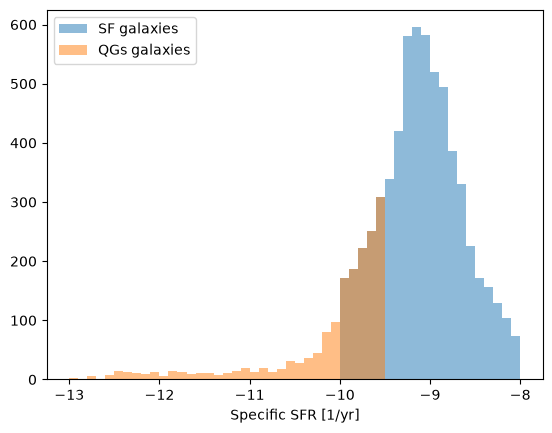

In [3]:
ssfr = np.log10(catOG['bayes.sfh.sfr']/catOG['bayes.stellar.m_star'])
newcat = catOG[ssfr>-10] ### starforming only
plt.hist(ssfr[ssfr>-10], bins = 50, range=(-13, -8), alpha = 0.5, label = 'SF galaxies')
newcat = catOG[ssfr<-9.5] ###  more quiescent
plt.hist(ssfr[ssfr<-9.5], bins = 50, range=(-13, -8), alpha = 0.5, label = 'QGs galaxies')
newcat = catOG
plt.xlabel('Specific SFR [1/yr]')
plt.legend()

The 1sigma relative error for u band is 5.8 %
The 1sigma relative error for g band is 8.8 %
The 1sigma relative error for r band is 8.6 %
The 1sigma relative error for i band is 9.8 %
The 1sigma relative error for z band is 8.8 %


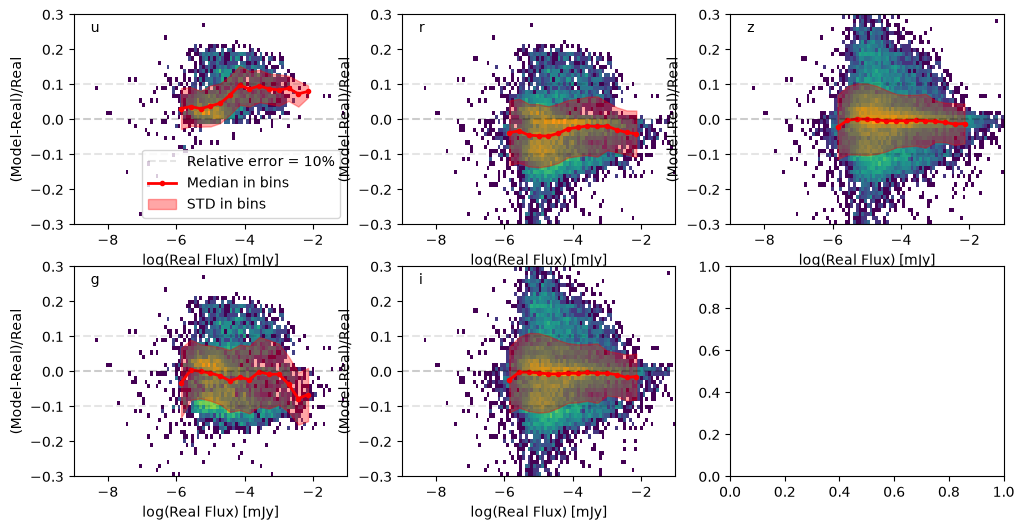

In [4]:
fig, axes = plt.subplots(2,3, figsize=(12,6))
testBands = ['u', 'g','r','i','z']
for j in range(len(testBands)):
    catModelData = Table.read('Uncertainties/fromModelData_sloan.sdss.%s.fits'%(testBands[j]))
    catModelData = join(catModelData, newcat, keys='id')
    if j<2: ny = 0
    elif j<4: ny = 1
    else:ny = 2
    ax = axes[j%2, ny]
    x = catModelData['SEDFlux']
    y = (catModelData['modelFlux']-x)/x
    print('The 1sigma relative error for %s band is %.1f'%(testBands[j], np.std(y)*100), '%')
    hist = ax.hist2d(np.log10(x),y, bins = (100,50), range=((-9, -1),(-0.3,0.3)), norm = 'log')
    ax.plot([-10,1],[0,0], c = 'k', ls = '--', zorder = 5, alpha = 0.2)
    ax.plot([-10,1],[0.1,0.1], c = 'k', ls = '--', zorder = 5, alpha = 0.1)
    ax.plot([-10,1],[-0.1,-0.1], c = 'k', ls = '--', zorder = 5, alpha = 0.1, label = 'Relative error = 10%')
    ax.set_xlabel('log(Real Flux) [mJy]')
    ax.set_ylabel('(Model-Real)/Real')
    ax.set_xlim(-9, -1)
    #ax.colorbar(hist[-1], label = 'Ngal')
    xbin = np.linspace(-6, -2, 15)
    ybin = np.zeros(len(xbin)-1)
    ybin_err = np.zeros(len(xbin)-1)
    for i in range(len(xbin)-1):
        dataHere = np.where((np.log10(x)>xbin[i])& (np.log10(x)<xbin[i+1]))[0]
        ybin[i] = np.median(y[dataHere])
        ybin_err[i] = np.std(y[dataHere])
    xbin = xbin[0:-1] + xbin[1]/2-xbin[0]/2
    ax.plot(xbin, ybin, c = 'r', lw = 2, marker = '.', label = 'Median in bins')
    ax.fill_between(xbin, ybin+ybin_err, ybin-ybin_err, color = 'r', alpha = 0.35, label = 'STD in bins')
    ax.text(-8.5, 0.25,testBands[j])
    if j == 0:
        ax.legend(loc = 'lower right')

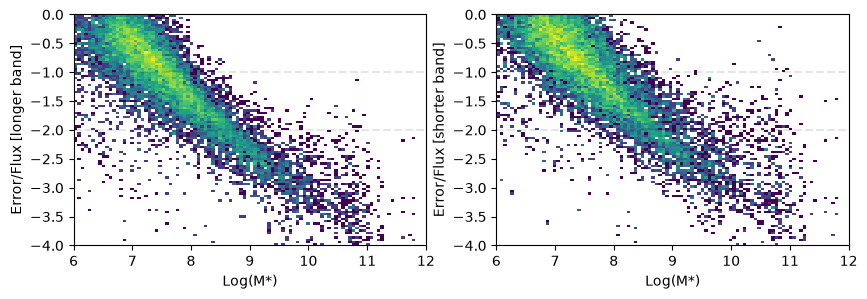

In [5]:
fig = plt.figure(figsize=(10,3))
x = np.log10(catModelData['bayes.stellar.m_star'])
plt.subplot(121)
longRelative = np.log10(catModelData['SEDFluxLong_err']/catModelData['SEDFluxLong'])
plt.hist2d(x, longRelative, range = ((6,12),(-4,0)), bins = 100, label = 'Longer band', norm = 'log')
plt.ylabel('Error/Flux [longer band]')
plt.xlabel('Log(M*)')
plt.axhline(y = -1, c = 'k', alpha = 0.1, ls = '--')
plt.axhline(y = -2, c = 'k', alpha = 0.1, ls = '--')
plt.subplot(122)
shortRelative = np.log10(catModelData['SEDFluxShort_err']/catModelData['SEDFluxShort'])
plt.hist2d(x, shortRelative, range = ((6,12),(-4,0)), bins = 100, label = 'Longer band', norm = 'log')
plt.ylabel('Error/Flux [shorter band]')
plt.xlabel('Log(M*)')
plt.axhline(y = -1, c = 'k', alpha = 0.1, ls = '--')
plt.axhline(y = -2, c = 'k', alpha = 0.1, ls = '--')